# Digitized annealing on an inspectable MaxCut instance

This notebook executes a linear annealing schedule on the four-vertex cycle. It starts in the ground state of a transverse-X driver, digitizes the time-dependent evolution into explicit one-qubit rotations and CX gates, and finally samples cut assignments in the computational basis.

The main parameters **$T=16$, $L=256$** and target **optimal-cut probability at least 0.95** are fixed before running the examples. A small time study and a separate step study diagnose this particular state preparation; they do not retune the main instance or establish a general adiabatic runtime guarantee. Numerical checks distinguish state error, cut-observable error, and finite-shot readout.

Use the pinned Python 3.12 environment. The notebook loads its own worktree module explicitly or a matching **annealing** `optimization.py` download beside it. Saved original outputs serve a static website without a live kernel. No device noise, mitigation, arbitrary-rotation synthesis or hardware runtime is claimed.

The adiabatic-computation proposal is credited to Farhi, Goldstone, Gutmann and Sipser (2000) {cite:p}`opt_adiabatic2000`. Continuous reference integration uses **SciPy 1.18.1**, BSD-3-Clause {cite:p}`opt_scipy1181`; Qiskit core, NumPy and Matplotlib are credited with their pinned releases in the parent chapter {cite:p}`opt_qiskit262,opt_numpy254,opt_matplotlib3112`. Our notebook, circuit implementation and figures are original and MIT-licensed.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import platform
import sys

cwd = Path.cwd().resolve()
candidates = [
    ("checkout", cwd / "src/openquantum/optimization.py"),
    ("checkout", cwd.parent / "src/openquantum/optimization.py"),
    ("standalone annealing download", cwd / "optimization.py"),
    ("standalone annealing download", cwd / "notebooks/optimization.py"),
]
selected = next(((kind, path.resolve()) for kind, path in candidates if path.is_file()), None)
if selected is None:
    raise FileNotFoundError("Save annealing/optimization.py beside this notebook, or run in its source checkout.")
source_kind, module_path = selected
spec = importlib.util.spec_from_file_location("optimization_annealing_notebook_source", module_path)
opt = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = opt
spec.loader.exec_module(opt)
assert Path(opt.__file__).resolve() == module_path
if not hasattr(opt, "run_annealing_demo"):
    raise ImportError("Use the annealing optimization.py download; older modules lack this workflow.")
# The actual source path remains in the kernel rather than saved private output.
print({"source": source_kind,
       "implementation_sha256": hashlib.sha256(module_path.read_bytes()).hexdigest(),
       "python": platform.python_version(),
       "packages": {name: importlib.metadata.version(name) for name in ("qiskit", "numpy", "matplotlib", "scipy")}})

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from IPython.display import display


{'source': 'checkout', 'implementation_sha256': 'a617b5e8d43b648427e5ceaa5e35d3f50ea14c02464465084f23f457ffb5855d', 'python': '3.12.14', 'packages': {'qiskit': '2.6.2', 'numpy': '2.5.4', 'matplotlib': '3.11.2', 'scipy': '1.18.1'}}


## Hamiltonians, input and angle convention

For the unweighted cycle $\mathcal E=\{(0,1),(1,2),(2,3),(0,3)\}$, define

$$C(z)=\sum_{(u,v)\in\mathcal E}[z_u\ne z_v],\qquad
H_D=-\sum_{q=0}^{3}X_q,\qquad
H_P=\frac12\sum_{(u,v)\in\mathcal E}Z_uZ_v=2I-C.$$

The time-dependent Hamiltonian is $H(s)=(1-s)H_D+sH_P$, with linear $s=t/T$ and $\hbar=1$. Energy and time are in the associated dimensionless units. Initial H gates prepare $|+\rangle^{\otimes4}$, the driver ground state. The two optimal cut strings `0101` and `1010` are a degenerate final ground space; success means total probability in that space.

For $\Delta t=T/L$ and midpoint $s_j=(j+1/2)/L$, each step applies a driver half-step, a problem full-step, and another driver half-step. With $R_P(\alpha)=e^{-i\alpha P/2}$, the chronological primitive gates are:

1. `rx(-dt*(1-s_j))` on every qubit;
2. `cx(u,v); rz(dt*s_j,v); cx(u,v)` for every edge;
3. the same RX half-step on every qubit.

The signs follow $H_D=-\sum X$: each driver half-step is $\exp(+i\Delta t(1-s_j)\sum X/2)$. The ZZ phase realizes $\exp(-i\Delta t s_j\sum ZZ/2)$. No opaque Hamiltonian evolution operation is hidden in the generated circuit.


In [2]:
edges = ((0, 1), (1, 2), (2, 3), (0, 3))
n_qubits = 4
basis_indices = np.arange(1 << n_qubits)
cut_values = np.array([sum(((z >> u) & 1) != ((z >> v) & 1) for u, v in edges)
                       for z in basis_indices], dtype=float)
np.testing.assert_array_equal(cut_values, opt.maxcut_values(n_qubits, edges))
optimal_mask = cut_values == cut_values.max()
assert cut_values.max() == 4
initial_state = np.ones(16, dtype=complex)/4
# Bit flips construct independent matrices in |q3 q2 q1 q0> order.
driver = -sum(np.eye(16, dtype=complex)[:, basis_indices ^ (1 << q)] for q in range(4))
zz_energies = np.array([.5*sum((1-2*((z >> u)&1))*(1-2*((z >> v)&1)) for u,v in edges)
                        for z in basis_indices])
np.testing.assert_array_equal(zz_energies, 2-cut_values)
problem = np.diag(zz_energies)
np.testing.assert_allclose(driver @ initial_state, -4*initial_state, atol=1e-14, rtol=0)
print({"classical_maximum_cut": float(cut_values.max()),
       "optimal_bitstrings": [f"{z:04b}" for z in basis_indices[optimal_mask]],
       "initial_driver_energy": float(np.vdot(initial_state, driver @ initial_state).real)})


def dense_strang(total_time, steps):
    # Classical 16d reference assembled independently of the circuit API.
    dt = total_time/steps
    eigenvalues, eigenvectors = np.linalg.eigh(driver)
    state = initial_state.copy()
    for j in range(steps):
        s = (j+.5)/steps
        half = (eigenvectors*np.exp(-1j*dt*(1-s)*eigenvalues/2)) @ eigenvectors.conj().T
        state = half @ state
        state *= np.exp(-1j*dt*s*zz_energies)
        state = half @ state
    return state


def continuous_reference(total_time):
    # Independent dense numerical solution of i d|psi>/dt=H(t/T)|psi>.
    solution = solve_ivp(lambda t, y: -1j*((1-t/total_time)*driver+(t/total_time)*problem) @ y,
                         (0, total_time), initial_state, method="DOP853", rtol=1e-11, atol=1e-13)
    assert solution.success, solution.message
    return solution.y[:, -1], {"method": "SciPy DOP853", "rtol": 1e-11, "atol": 1e-13,
                              "function_evaluations": solution.nfev,
                              "norm_drift": float(abs(np.vdot(solution.y[:, -1], solution.y[:, -1]).real-1))}


def state_observables(state):
    probabilities = np.abs(state)**2/np.vdot(state,state).real
    return {"expected_cut": float(probabilities @ cut_values),
            "optimal_cut_probability": float(probabilities[optimal_mask].sum())}


def comparison(state, reference):
    fidelity = abs(np.vdot(state, reference))**2/(np.vdot(state,state).real*np.vdot(reference,reference).real)
    return {"state_infidelity": float(max(0., 1-fidelity)),
            "absolute_cut_mean_error": abs(state_observables(state)["expected_cut"]-state_observables(reference)["expected_cut"])}



def independent_gate_circuit(total_time, steps, measure=False):
    # A separate explicit construction for differential checking on four qubits.
    if not 0 < total_time <= 16 or not isinstance(steps, int) or not 1 <= steps <= 256:
        raise ValueError("this notebook's independent checker is bounded to T<=16 and 1..256 steps")
    dt = total_time/steps
    circuit = QuantumCircuit(4)
    circuit.h(range(4))
    for j in range(steps):
        s = (j+.5)/steps
        circuit.rx(-dt*(1-s), range(4))
        for u,v in edges:
            circuit.cx(u,v)
            circuit.rz(dt*s,v)
            circuit.cx(u,v)
        circuit.rx(-dt*(1-s), range(4))
    if measure:
        circuit.measure_all()
    return circuit


{'classical_maximum_cut': 4.0, 'optimal_bitstrings': ['0101', '1010'], 'initial_driver_energy': -4.0}


## Fixed run and diagnostic studies

The next cell executes the full bounded module workflow. The main example uses $T=16$, $L=256$. The time study uses $T=1,2,4,8,16$ with $L=256$, while the discretization study holds $T=4$ and uses $L=8,16,32,64,128$.

The continuous solution is a **dense numerical reference**, with recorded solver tolerances and normalization drift. The comparisons concern the prepared state and its cut observable, not an operator-norm error for all input states. Readout is a separate ideal all-Z protocol with 4,096 shots for each seed `7`, `19`, and `41` in the annealing stream namespace.


In [3]:
annealing = opt.run_annealing_demo()
assert annealing["task"]["n_qubits"] == 4
assert {tuple(edge) for edge in annealing["task"]["edges"]} == set(edges)
assert annealing["target"]["predeclared_total_time"] == 16.
assert annealing["target"]["predeclared_steps"] == 256
assert annealing["target"]["ideal_optimal_probability_at_least"] == .95
np.testing.assert_array_equal(annealing["reference"]["cut_values"], cut_values)
print({"module_workflow_CPU_wall_seconds": annealing["workflow_wall_seconds"],
       "module_timing_scope": annealing["timing_scope"],
       "main_target_met": annealing["target"]["achieved"],
       "modeled_readout_preparations": annealing["total_preparations"]})


{'module_workflow_CPU_wall_seconds': 1.20987667899999, 'module_timing_scope': 'CPU circuit simulation, dense numerical references and ideal seeded sampling; not QPU time', 'main_target_met': True, 'modeled_readout_preparations': 12288}


## Main state and independent numerical checks

For each diagnostic case, the circuit generator, the independent gate construction above, and the separately assembled dense Strang matrices must agree on the prepared state. The continuous reference solves the time-dependent Schrödinger equation with DOP853; its tolerances and normalization drift are recorded rather than treating it as a symbolic exact answer.

$T$ denotes **Hamiltonian evolution time**, not a hardware gate runtime. Infidelity compares the particular prepared states; cut-mean error compares one observable. Neither quantity is a bound on the complete evolution operator for every possible input.


In [4]:
main_circuit = opt.build_annealing_circuit(4, edges, 16., 256)
main_state = Statevector.from_instruction(main_circuit).data
independent_state = Statevector.from_instruction(independent_gate_circuit(16., 256)).data
strang_state = dense_strang(16., 256)
np.testing.assert_allclose(abs(np.vdot(main_state, independent_state)), 1., rtol=0, atol=1e-10)
np.testing.assert_allclose(abs(np.vdot(main_state, strang_state)), 1., rtol=0, atol=1e-10)
main_continuous, main_solver = continuous_reference(16.)
main_observables = state_observables(main_state)
main_errors = comparison(main_state, main_continuous)
np.testing.assert_allclose(annealing["main"]["expected_cut"], main_observables["expected_cut"], rtol=0, atol=1e-11)
np.testing.assert_allclose(annealing["main"]["optimal_probability"], main_observables["optimal_cut_probability"], rtol=0, atol=1e-11)
np.testing.assert_allclose(annealing["main"]["state_infidelity"], main_errors["state_infidelity"], rtol=0, atol=1e-10)
assert annealing["target"]["achieved"] == (main_observables["optimal_cut_probability"] >= .95)
assert dict(main_circuit.count_ops()) == {"h": 4, "rx": 2048, "cx": 2048, "rz": 1024}
print({"fixed_T": 16., "fixed_steps": 256, **main_observables,
       "target_probability_at_least": .95, "target_met": main_observables["optimal_cut_probability"] >= .95,
       "continuous_reference": state_observables(main_continuous),
       "state_specific_errors": main_errors, "independent_solver": main_solver,
       "logical_qubits": main_circuit.num_qubits, "primitive_gate_counts": dict(main_circuit.count_ops())})


{'fixed_T': 16.0, 'fixed_steps': 256, 'expected_cut': 3.974032281211605, 'optimal_cut_probability': 0.9870227285630317, 'target_probability_at_least': 0.95, 'target_met': True, 'continuous_reference': {'expected_cut': 3.9740596314383936, 'optimal_cut_probability': 0.987036430833905}, 'state_specific_errors': {'state_infidelity': 1.1932247190316048e-08, 'absolute_cut_mean_error': 2.7350226788680487e-05}, 'independent_solver': {'method': 'SciPy DOP853', 'rtol': 1e-11, 'atol': 1e-13, 'function_evaluations': 1970, 'norm_drift': 6.09734485124136e-13}, 'logical_qubits': 4, 'primitive_gate_counts': {'rx': 2048, 'cx': 2048, 'rz': 1024, 'h': 4}}


## A coarse two-step illustration

This is an actual **$T=16$, $L=2$** circuit drawn from the same generator, with final all-Z measurements. It illustrates gate order and coefficients. It is **not** the 256-step main circuit whose quality is reported above; its coarse discretization is not presented as a validated high-accuracy approximation.


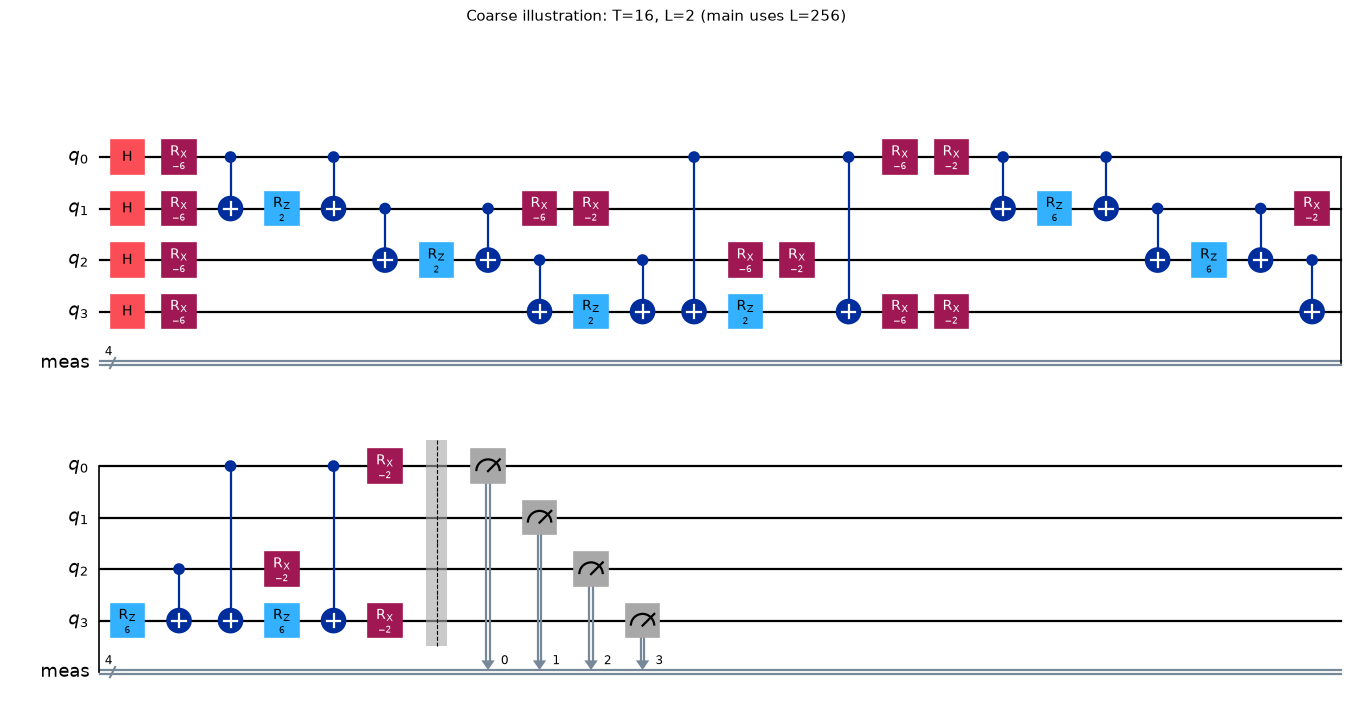

In [5]:
coarse_circuit = opt.build_annealing_circuit(4, edges, 16., 2, measure=True)
coarse_state = Statevector.from_instruction(coarse_circuit.remove_final_measurements(inplace=False)).data
np.testing.assert_allclose(abs(np.vdot(coarse_state, dense_strang(16., 2))), 1., rtol=0, atol=1e-12)
figure = coarse_circuit.draw(output="mpl", fold=24, scale=.8)
figure.suptitle("Coarse illustration: T=16, L=2 (main uses L=256)", y=1.02, fontsize=11)
display(figure)
plt.close(figure)


## Time and discretization studies

The left plot holds $L=256$ and changes the evolution time. Its probability trend is empirical for this instance and schedule. The right plot holds $T=4$ and changes the number of steps, comparing against the continuous reference state. Both plots show executed numerical results. They neither select new main parameters nor certify an asymptotic error or runtime law.


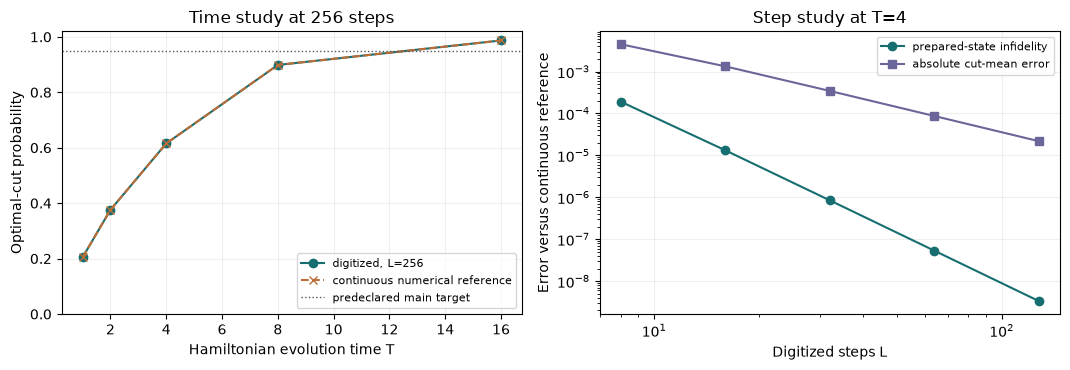

In [6]:
time_rows = []
reference_cache = {16.: (main_continuous, main_solver)}
for total_time in (1., 2., 4., 8., 16.):
    circuit = opt.build_annealing_circuit(4, edges, total_time, 256)
    state = Statevector.from_instruction(circuit).data
    reference, solver = reference_cache.get(total_time, (None, None))
    if reference is None:
        reference, solver = continuous_reference(total_time)
        reference_cache[total_time] = (reference, solver)
    dense = dense_strang(total_time, 256)
    np.testing.assert_allclose(abs(np.vdot(state,dense)), 1., rtol=0, atol=1e-10)
    time_rows.append({"T": total_time, **state_observables(state),
                      "continuous_optimal_probability": state_observables(reference)["optimal_cut_probability"],
                      **comparison(state, reference), "solver": solver})
reference4, _ = reference_cache[4.]
step_rows = []
for steps in (8, 16, 32, 64, 128):
    state = Statevector.from_instruction(opt.build_annealing_circuit(4, edges, 4., steps)).data
    np.testing.assert_allclose(abs(np.vdot(state,dense_strang(4.,steps))), 1., rtol=0, atol=1e-10)
    step_rows.append({"steps": steps, **comparison(state, reference4)})
for independent, canonical in zip(time_rows, annealing["time_study"]):
    assert independent["T"] == canonical["total_time"]
    np.testing.assert_allclose(independent["optimal_cut_probability"], canonical["digitized_optimal_probability"], rtol=0, atol=1e-11)
    np.testing.assert_allclose(independent["continuous_optimal_probability"], canonical["continuous_optimal_probability"], rtol=0, atol=1e-10)
for independent, canonical in zip(step_rows, annealing["step_study"]):
    assert independent["steps"] == canonical["steps"]
    np.testing.assert_allclose(independent["state_infidelity"], canonical["state_infidelity"], rtol=0, atol=1e-10)
    np.testing.assert_allclose(independent["absolute_cut_mean_error"], canonical["cut_mean_absolute_error"], rtol=0, atol=1e-10)
fig, axes = plt.subplots(1,2,figsize=(10.8,3.8))
axes[0].plot([row["T"] for row in time_rows],[row["optimal_cut_probability"] for row in time_rows],"o-",color="#176e70",label="digitized, L=256")
axes[0].plot([row["T"] for row in time_rows],[row["continuous_optimal_probability"] for row in time_rows],"x--",color="#bd6d36",label="continuous numerical reference")
axes[0].axhline(.95,color="#555555",ls=":",lw=1,label="predeclared main target")
axes[0].set(xlabel="Hamiltonian evolution time T",ylabel="Optimal-cut probability",title="Time study at 256 steps",ylim=(0,1.02))
axes[0].legend(fontsize=8)
axes[1].loglog([row["steps"] for row in step_rows],[row["state_infidelity"] for row in step_rows],"o-",color="#176e70",label="prepared-state infidelity")
axes[1].loglog([row["steps"] for row in step_rows],[row["absolute_cut_mean_error"] for row in step_rows],"s-",color="#6a6699",label="absolute cut-mean error")
axes[1].set(xlabel="Digitized steps L",ylabel="Error versus continuous reference",title="Step study at T=4")
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout()
display(fig)
plt.close(fig)


## Degeneracy and the preserved symmetry sector

The full spectral gap $E_1-E_0$ reaches zero at $s=1$, because the two maximum-cut basis states are degenerate. The ideal Hamiltonians commute with the global bit flip $G=X^{\otimes4}$, and the initial state is in its $G=+1$ sector. We therefore also inspect the first gap within that sector.

The sector calculation is an **eight-dimensional classical eigensolver reduction**. The physical circuit still has four logical qubits. Positivity on a 201-point mesh is a numerical observation, not a proven lower bound between mesh points, an adiabatic theorem, a general runtime guarantee, or a promise that hardware noise preserves this symmetry.


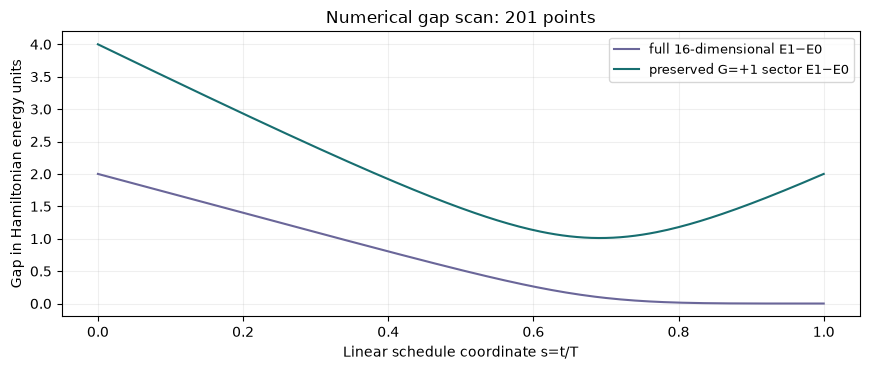

{'full_endpoint_gap': 0.0, 'scanned_plus_sector_minimum_gap': 1.0109390446842772, 'plus_sector_dimension': 8, 'actual_circuit_logical_qubits': 4}


In [7]:
global_flip = np.eye(16)[:, basis_indices ^ 15]
np.testing.assert_allclose(driver@global_flip, global_flip@driver, rtol=0, atol=1e-14)
np.testing.assert_allclose(problem@global_flip, global_flip@problem, rtol=0, atol=1e-14)
np.testing.assert_allclose(global_flip@initial_state, initial_state, rtol=0, atol=1e-14)
np.testing.assert_allclose(global_flip@main_state, main_state, rtol=0, atol=1e-10)
plus_basis = np.column_stack([(np.eye(16)[:, z]+np.eye(16)[:, z ^ 15])/np.sqrt(2) for z in range(8)])
np.testing.assert_allclose(plus_basis.T@plus_basis, np.eye(8), rtol=0, atol=1e-14)
np.testing.assert_allclose(global_flip@plus_basis, plus_basis, rtol=0, atol=1e-14)
mesh = np.linspace(0,1,201)
full_gap, sector_gap = [], []
for s in mesh:
    hamiltonian = (1-s)*driver+s*problem
    full_eigenvalues = np.linalg.eigvalsh(hamiltonian)
    sector_eigenvalues = np.linalg.eigvalsh(plus_basis.T@hamiltonian@plus_basis)
    full_gap.append(float(full_eigenvalues[1]-full_eigenvalues[0]))
    sector_gap.append(float(sector_eigenvalues[1]-sector_eigenvalues[0]))
assert abs(full_gap[-1]) < 1e-12
assert min(sector_gap) > 0
np.testing.assert_allclose(sector_gap[-1], 2., rtol=0, atol=1e-12)
for s, full, sector, canonical in zip(mesh, full_gap, sector_gap, annealing["gap_scan"]):
    np.testing.assert_allclose([s,full,sector],[canonical["s"],canonical["full_gap"],canonical["plus_sector_gap"]], rtol=0, atol=1e-10)
fig, ax = plt.subplots(figsize=(8.8,3.8))
ax.plot(mesh,full_gap,color="#6a6699",label="full 16-dimensional E1−E0")
ax.plot(mesh,sector_gap,color="#176e70",label="preserved G=+1 sector E1−E0")
ax.set(xlabel="Linear schedule coordinate s=t/T",ylabel="Gap in Hamiltonian energy units",title="Numerical gap scan: 201 points")
ax.legend(fontsize=9)
ax.grid(alpha=.2)
fig.tight_layout()
display(fig)
plt.close(fig)
print({"full_endpoint_gap": full_gap[-1], "scanned_plus_sector_minimum_gap": min(sector_gap),
       "plus_sector_dimension":8,"actual_circuit_logical_qubits":4})


## Ideal all-Z readout and explicit count checks

The fixed main state is read out with 4,096 shots per seed `7`, `19`, and `41`. These are ideal multinomial counts generated classically from the circuit probabilities, not physical circuit executions. Every bitstring scores all four edge contributions jointly.

We reconstruct the cut means and sample variances from those counts, plus the number and fraction of optimal cuts and the best cut observed. Plot error bars show one estimated standard error, not a rigorous confidence interval. Positive-probability optimal output, finite-shot estimate uncertainty, state approximation error and physical faults are separate questions.


In [8]:
assert [row["seed"] for row in annealing["readout"]] == [7,19,41]
for row in annealing["readout"]:
    assert row["shots"] == 4096
    assert sum(row["counts"].values()) == row["shots"]
    mean = sum(count*cut_values[int(bits,2)] for bits,count in row["counts"].items())/row["shots"]
    variance = sum(count*(cut_values[int(bits,2)]-mean)**2 for bits,count in row["counts"].items())/(row["shots"]-1)
    optimal_count = sum(count for bits,count in row["counts"].items() if cut_values[int(bits,2)] == 4)
    np.testing.assert_allclose([row["cut_mean"],row["sample_variance"],row["cut_standard_error"]],
                               [mean,variance,np.sqrt(variance/row["shots"])], rtol=0, atol=1e-12)
    assert row["optimal_count"] == optimal_count
    assert row["optimal_frequency"] == optimal_count/row["shots"]
    assert row["best_observed_cut"] == max(int(cut_values[int(bits,2)]) for bits in row["counts"])
    assert row["rng"]["entropy"] == [row["seed"],4]
    assert row["rng"]["spawn_key"] == [1,0,0]
    print({"seed":row["seed"],"modeled_shots":row["shots"],"cut_mean":float(mean),
           "cut_mean_estimated_SE":row["cut_standard_error"],"optimal_count":optimal_count,
           "optimal_frequency":row["optimal_frequency"],"best_cut":row["best_observed_cut"]})


{'seed': 7, 'modeled_shots': 4096, 'cut_mean': 3.9765625, 'cut_mean_estimated_SE': 0.003363442172289721, 'optimal_count': 4048, 'optimal_frequency': 0.98828125, 'best_cut': 4}
{'seed': 19, 'modeled_shots': 4096, 'cut_mean': 3.97265625, 'cut_mean_estimated_SE': 0.003629341132210224, 'optimal_count': 4040, 'optimal_frequency': 0.986328125, 'best_cut': 4}
{'seed': 41, 'modeled_shots': 4096, 'cut_mean': 3.9716796875, 'cut_mean_estimated_SE': 0.003692667879508286, 'optimal_count': 4038, 'optimal_frequency': 0.98583984375, 'best_cut': 4}


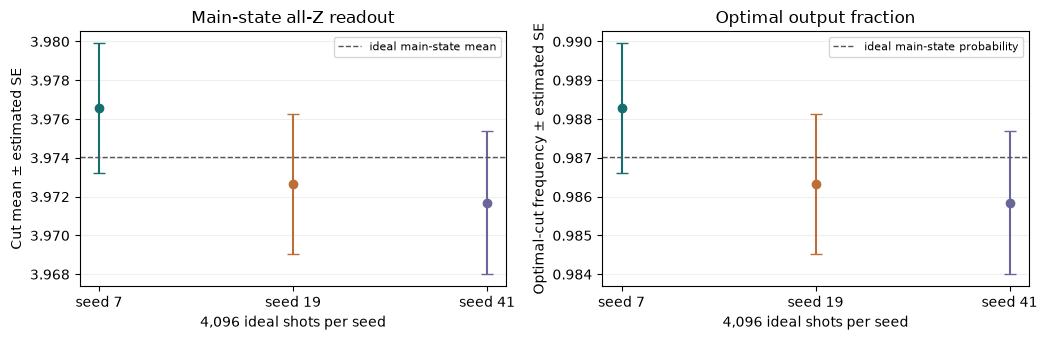

In [9]:
colors=("#176e70","#bd6d36","#6a6699")
fig,axes=plt.subplots(1,2,figsize=(10.6,3.5))
for index,(color,row) in enumerate(zip(colors,annealing["readout"])):
    axes[0].errorbar(index,row["cut_mean"],yerr=row["cut_standard_error"],color=color,fmt="o",capsize=4)
    frequency=row["optimal_frequency"]
    axes[1].errorbar(index,frequency,yerr=np.sqrt(frequency*(1-frequency)/row["shots"]),color=color,fmt="o",capsize=4)
axes[0].axhline(main_observables["expected_cut"],color="#555555",ls="--",lw=1,label="ideal main-state mean")
axes[1].axhline(main_observables["optimal_cut_probability"],color="#555555",ls="--",lw=1,label="ideal main-state probability")
axes[0].set(ylabel="Cut mean ± estimated SE",title="Main-state all-Z readout")
axes[1].set(ylabel="Optimal-cut frequency ± estimated SE",title="Optimal output fraction")
for ax in axes:
    ax.set(xticks=range(3),xticklabels=["seed 7","seed 19","seed 41"],xlabel="4,096 ideal shots per seed")
    ax.ticklabel_format(axis="y",style="plain",useOffset=False)
    ax.legend(fontsize=8)
    ax.grid(axis="y",alpha=.2)
fig.tight_layout()
display(fig)
plt.close(fig)


## Logical protocol cost and exclusions

The readout workload is **12,288 complete main-state preparations** and **49,152 individual qubit readouts**. Every preparation includes four initial H gates, both driver half-steps in each of 256 segments, all explicit ZZ phases, and final measurements. The dense reference and diagnostic studies are classical computations with zero protocol shots. The coarse circuit figure does not replace the main circuit in these counts.

These are shot-weighted logical operations for the stated ideal protocol. They are not hardware runtime measurements. Arbitrary rotations still need a declared synthesis contract; reset latency, routing, control feedback and physical error correction remain excluded. $T=16$ is not a physical execution-time estimate, and the eight-dimensional symmetry reduction does not reduce the actual circuit's four logical qubits.


In [10]:
ledger=opt.annealing_run_resources(annealing)
assert ledger["logical_qubits"] == 4
assert ledger["total_preparations"] == 12_288
assert ledger["measured_qubit_readouts"] == 49_152
assert ledger["rotation_count"] == 3072
counts=ledger["per_preparation_gate_counts"]
assert {gate:counts[gate] for gate in ("h","rx","rz","cx","measure")} == {"h":4,"rx":2048,"rz":1024,"cx":2048,"measure":4}
for gate in ("h","rx","rz","cx","measure"):
    assert ledger["shot_weighted_gate_counts"][gate] == counts[gate]*12_288
assert ledger["physical_resource_estimate"] is None
print({"logical_qubits":ledger["logical_qubits"],"modeled_full_preparations":ledger["total_preparations"],
       "modeled_qubit_measurements":ledger["measured_qubit_readouts"],
       "per_preparation_primitive_counts":{gate:counts[gate] for gate in ("h","rx","rz","cx","measure")},
       "rotation_synthesis":"pending","physical_resource_estimate":ledger["physical_resource_estimate"]})
print("Independent circuit, dense reference, symmetry, readout and full logical protocol checks passed.")


{'logical_qubits': 4, 'modeled_full_preparations': 12288, 'modeled_qubit_measurements': 49152, 'per_preparation_primitive_counts': {'h': 4, 'rx': 2048, 'rz': 1024, 'cx': 2048, 'measure': 4}, 'rotation_synthesis': 'pending', 'physical_resource_estimate': None}
Independent circuit, dense reference, symmetry, readout and full logical protocol checks passed.
